# Vehicle Classification – 01 · Exploratory Data Analysis

**Task:** predict `vehicle_class` – 0 = Sedan, 1 = SUV, 2 = Sports Car – from 20 numeric vehicle
specifications. Submissions are scored on accuracy.

This notebook covers sections 2–3 of the report:

1. Dataset overview
2. Data quality: duplicates and the identifier
3. Target variable
4. Which features separate the classes
5. Correlation structure
6. PCA
7. Clipped measurements
8. Train vs test: measuring the extra noise in the test file
9. Summary

Next: `02_Preprocessing.ipynb`, then `03_Models.ipynb`.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency, chisquare, ks_2samp
from sklearn.decomposition import PCA
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

CLASS = {0: ("Sedan", "#2a78d6"), 1: ("SUV", "#eb6834"), 2: ("Sports Car", "#1baf7a")}
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.edgecolor": AXIS, "axes.linewidth": 0.6,
    "axes.labelcolor": INK2, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "xtick.major.size": 0, "ytick.major.size": 0, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "legend.frameon": False})

## 1. Dataset overview

Three files were provided: the training data (with the target), the test data (without it) and
the required submission format.

In [2]:
TARGET, ID = "vehicle_class", "vehicle_id"
train_raw = pd.read_csv("data/vehicle_train_10000.csv")
test = pd.read_csv("data/vehicle_test.csv")
sample = pd.read_csv("data/vehicle_sample_submission.csv")
FEATURES = [c for c in train_raw.columns if c not in (ID, TARGET)]

print(f"train {train_raw.shape}   test {test.shape}   sample submission {sample.shape}")
print(f"{len(FEATURES)} features, dtypes: {sorted(set(map(str, train_raw[FEATURES].dtypes)))}")
print("missing values   train:", int(train_raw.isna().sum().sum()), "  test:", int(test.isna().sum().sum()))
train_raw.head()

train (10000, 22)   test (2500, 21)   sample submission (2500, 2)
20 features, dtypes: ['float64']
missing values   train: 0   test: 0


,vehicle_id,engine_displacement_l,horsepower_hp,vehicle_weight_kg,wheelbase_mm,vehicle_length_mm,vehicle_width_mm,vehicle_height_mm,fuel_tank_capacity_l,city_fuel_efficiency_kmpl,highway_fuel_efficiency_kmpl,engine_cylinders,torque_nm,ground_clearance_mm,turning_radius_m,cargo_capacity_l,acceleration_0_100_kmh_s,braking_distance_m,tire_width_mm,drag_coefficient,battery_capacity_kwh,vehicle_class
0,1,2.56,290.0,1532.0,2737.0,4538.0,1814.0,1544.0,65.0,9.69,13.86,7.0,438.0,197.0,6.05,656.0,5.87,43.0,267.0,0.34,79.0,2
1,2,2.70,350.0,1529.0,2726.0,4473.0,1848.0,1636.0,62.0,10.35,14.32,7.0,441.0,251.0,5.30,513.0,6.48,41.0,247.0,0.28,76.0,2
2,3,2.50,335.0,1100.0,2504.0,3900.0,1650.0,1251.0,35.0,13.70,17.60,7.0,471.0,110.0,5.58,150.0,3.90,29.0,261.0,0.23,89.0,2
3,4,3.00,345.0,2069.0,3053.0,5134.0,2036.0,1572.0,81.0,10.72,16.45,7.0,478.0,168.0,6.36,626.0,6.20,51.0,283.0,0.37,60.0,1
4,5,1.59,155.0,1574.0,2791.0,4678.0,1804.0,1492.0,60.0,13.55,16.71,4.0,235.0,179.0,5.43,447.0,10.15,47.0,201.0,0.34,43.0,1


In [3]:
train_raw[FEATURES].describe().T[["mean", "std", "min", "50%", "max"]].round(2)

,mean,std,min,50%,max
engine_displacement_l,2.43,0.61,0.90,2.43,4.44
horsepower_hp,296.50,95.56,90.00,294.00,550.00
vehicle_weight_kg,1636.40,306.18,1100.00,1604.00,2600.00
wheelbase_mm,2778.06,172.35,2400.00,2756.00,3300.00
vehicle_length_mm,4660.04,366.06,3900.00,4622.00,5400.00
vehicle_width_mm,1836.67,117.74,1650.00,1824.00,2050.00
vehicle_height_mm,1528.94,145.98,1250.00,1530.00,2050.00
fuel_tank_capacity_l,61.10,14.51,35.00,60.00,90.00
city_fuel_efficiency_kmpl,11.61,2.57,7.00,11.56,20.87
highway_fuel_efficiency_kmpl,15.85,2.50,9.00,15.83,24.07


## 2. Data quality: duplicates and the identifier

The brief warns that the training data contains duplicate vehicle measurements, and that
`vehicle_id` identifies a record rather than describing the vehicle.

In [4]:
print(f"duplicated vehicle_id                  : {train_raw[ID].duplicated().sum()}")
print(f"duplicated measurements                : {train_raw.duplicated(subset=FEATURES).sum()}")
dup = train_raw.duplicated(subset=FEATURES + [TARGET]).sum()
print(f"duplicated measurements + same label   : {dup}  ({dup / len(train_raw):.0%} of the rows)")
print(f"vehicle_id overlap between train/test  : {len(set(train_raw[ID]) & set(test[ID]))}")

train = train_raw.drop_duplicates(subset=FEATURES + [TARGET]).reset_index(drop=True)
X, y = train[FEATURES].to_numpy(float), train[TARGET].to_numpy(int)
X_test = test[FEATURES].to_numpy(float)
LO, HI = X.min(0), X.max(0)
print(f"\nrows after de-duplication: {len(train):,}")

duplicated vehicle_id                  : 0
duplicated measurements                : 2500
duplicated measurements + same label   : 2500  (25% of the rows)
vehicle_id overlap between train/test  : 0

rows after de-duplication: 7,500


Every duplicated measurement carries the same label, so removing the copies loses no information.
`02_Preprocessing` shows how much they would inflate cross-validation if they stayed.

## 3. Target variable

In [5]:
counts = train[TARGET].value_counts().sort_index()
display(pd.DataFrame({"class": [CLASS[c][0] for c in counts.index], "vehicles": counts.values,
                      "share %": (counts.values / len(train) * 100).round(2)}, index=counts.index))
print(f"majority-class baseline: {counts.max() / len(train):.2%}  ->  the classes are balanced, "
      "so accuracy is a fair metric")

,class,vehicles,share %
vehicle_class,,,
0,Sedan,2539,33.85
1,SUV,2490,33.20
2,Sports Car,2471,32.95


majority-class baseline: 33.85%  ->  the classes are balanced, so accuracy is a fair metric


## 4. Which features separate the classes

The one-way ANOVA F statistic compares the spread *between* the class means with the spread
*within* each class. The last column is the share of rows clipped to a fixed limit (section 7).

In [6]:
F, _ = f_classif(X, y)
anova = pd.DataFrame({"ANOVA F": F, "% rows on a clip limit": ((X == LO).mean(0) + (X == HI).mean(0)) * 100},
                     index=FEATURES).sort_values("ANOVA F", ascending=False)
anova.insert(0, "rank", range(1, len(anova) + 1))
anova.round(1)

,rank,ANOVA F,% rows on a clip limit
battery_capacity_kwh,1,6239.4,0.0
braking_distance_m,2,6073.1,7.0
acceleration_0_100_kmh_s,3,5165.0,7.1
vehicle_width_mm,4,5068.2,11.6
wheelbase_mm,5,4908.7,0.5
vehicle_length_mm,6,4528.8,3.9
vehicle_weight_kg,7,4270.7,3.0
drag_coefficient,8,3754.3,2.2
fuel_tank_capacity_l,9,3690.1,7.1
horsepower_hp,10,2648.1,1.5


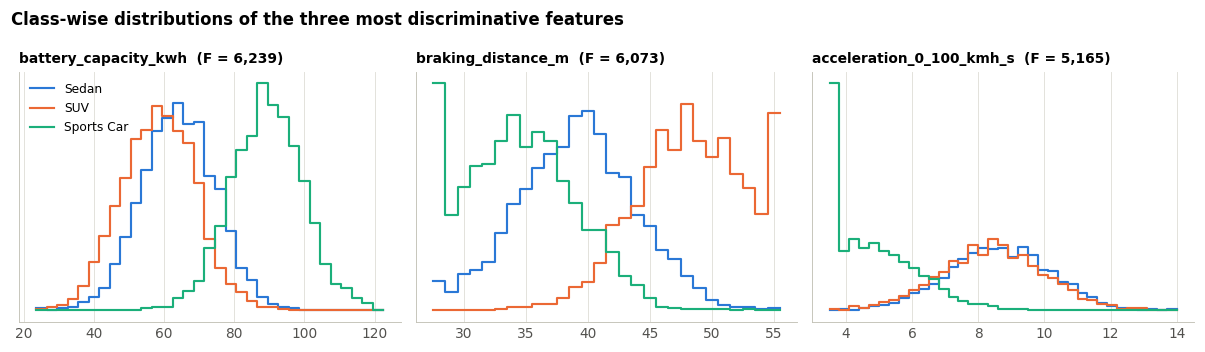

In [7]:
top = [FEATURES.index(f) for f in anova.index[:3]]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, j in zip(axes, top):
    lo, hi = X[:, j].min(), X[:, j].max()
    if np.all(np.round(X[:, j]) == X[:, j]):            # whole numbers: integer-aligned bins
        step = max(1, int(np.ceil((hi - lo) / 34)))
        bins = np.arange(lo - 0.5, hi + step + 0.5, step)
    else:
        bins = np.linspace(lo, hi, 36)
    for c, (name, col) in CLASS.items():
        h, e = np.histogram(X[y == c, j], bins=bins, density=True)
        ax.plot(np.repeat(e, 2)[1:-1], np.repeat(h, 2), color=col, lw=1.4, label=name)
    ax.set_title(f"{FEATURES[j]}  (F = {F[j]:,.0f})", fontsize=9)
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Class-wise distributions of the three most discriminative features", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
plt.show()

Battery capacity and acceleration isolate sports cars, braking distance separates SUVs, and
sedans sit in the middle – the pattern behind most classification errors later on.

## 5. Correlation structure

In [8]:
C = np.corrcoef(X, rowvar=False)
iu = np.triu_indices(len(FEATURES), 1)
pairs = pd.DataFrame({"feature A": np.array(FEATURES)[iu[0]], "feature B": np.array(FEATURES)[iu[1]],
                      "r": C[iu]})
pairs = pairs.reindex(pairs["r"].abs().sort_values(ascending=False).index).reset_index(drop=True)
print(f"{(pairs['r'].abs() > 0.5).sum()} of {len(pairs)} feature pairs have |r| > 0.5")
pairs.head(8).round(3)

90 of 190 feature pairs have |r| > 0.5


,feature A,feature B,r
0,horsepower_hp,torque_nm,0.959
1,engine_displacement_l,torque_nm,0.952
2,wheelbase_mm,vehicle_width_mm,0.952
3,engine_displacement_l,horsepower_hp,0.950
4,wheelbase_mm,vehicle_length_mm,0.949
5,vehicle_weight_kg,wheelbase_mm,0.945
6,vehicle_length_mm,vehicle_width_mm,0.937
7,vehicle_weight_kg,vehicle_length_mm,0.935


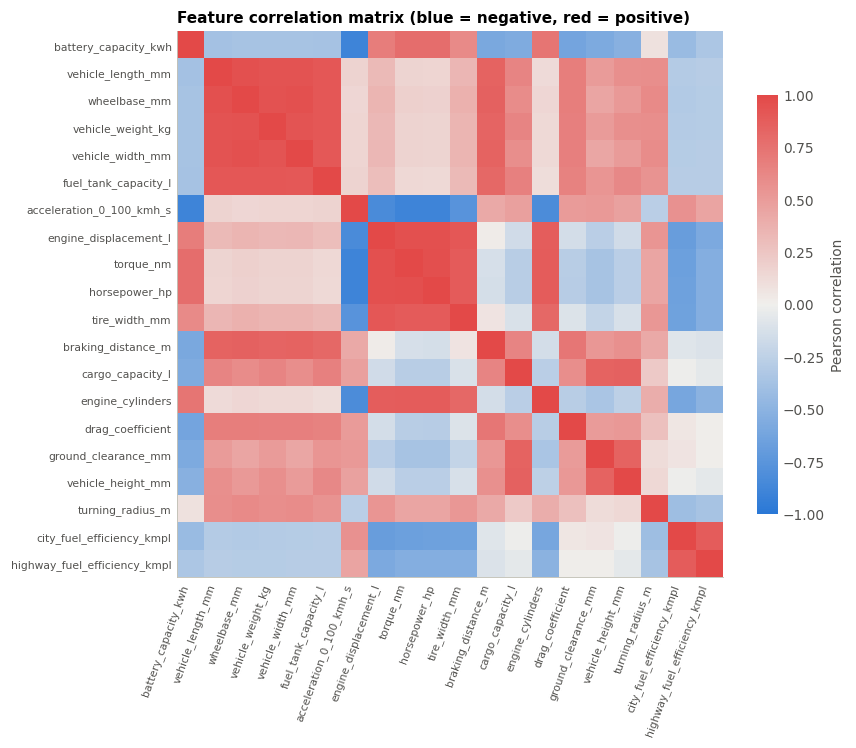

In [9]:
order = np.argsort(-np.abs(C).sum(0))
cmap = LinearSegmentedColormap.from_list("bluegrayred", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(8, 6.6))
im = ax.imshow(C[np.ix_(order, order)], cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(20), [FEATURES[i] for i in order], rotation=70, ha="right", fontsize=7)
ax.set_yticks(range(20), [FEATURES[i] for i in order], fontsize=7)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.75)
cb.outline.set_visible(False)
cb.set_label("Pearson correlation")
ax.set_title("Feature correlation matrix (blue = negative, red = positive)")
plt.show()

Two large blocks appear: **size** (length, wheelbase, weight, width, fuel tank) and **power**
(displacement, torque, horsepower, tire width). Correlations near 0.95 badly violate the
independence assumption of Naive Bayes (see `03_Models`, section 2.3).

## 6. PCA

variance explained by each component (%): [41.1 38.4  6.   4.   2.4  1.6  0.9  0.8  0.7  0.7  0.6  0.6  0.5  0.4
  0.3  0.3  0.3  0.2  0.2  0.2]
first two components: 41% + 38% = 79%
condition number (largest / smallest eigenvalue): 265


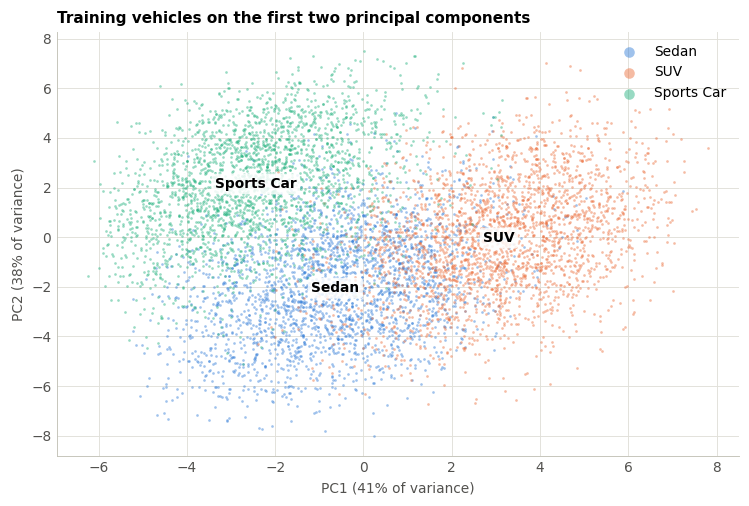

In [10]:
Z = StandardScaler().fit_transform(X)
pca = PCA().fit(Z)
ev = pca.explained_variance_
ratio = pca.explained_variance_ratio_ * 100
print("variance explained by each component (%):", np.round(ratio, 1))
print(f"first two components: {ratio[0]:.0f}% + {ratio[1]:.0f}% = {ratio[:2].sum():.0f}%")
print(f"condition number (largest / smallest eigenvalue): {ev[0] / ev[-1]:.0f}")

T = pca.transform(Z)[:, :2]
fig, ax = plt.subplots(figsize=(8, 5))
for c, (name, col) in CLASS.items():
    ax.scatter(T[y == c, 0], T[y == c, 1], s=3, color=col, alpha=0.45, linewidths=0, label=name)
for c, (name, col) in CLASS.items():
    cx, cy = T[y == c].mean(0)
    ax.annotate(name, (cx, cy), ha="center", va="center", fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.85))
ax.set_xlabel(f"PC1 ({ratio[0]:.0f}% of variance)")
ax.set_ylabel(f"PC2 ({ratio[1]:.0f}% of variance)")
ax.legend(markerscale=4, loc="upper right")
ax.set_title("Training vehicles on the first two principal components")
plt.show()

The classes are overlapping clouds: SUVs on the right, sports cars upper-left, and **sedans in
the middle, overlapping both**. The problem is close to linearly separable, but some error is
unavoidable.

## 7. Clipped measurements

Many features are clipped to fixed limits, which creates spikes of identical values.

In [11]:
rows = []
for j, f in enumerate(FEATURES):
    lo_tr, hi_tr = np.mean(X[:, j] == LO[j]) * 100, np.mean(X[:, j] == HI[j]) * 100
    if max(lo_tr, hi_tr) > 1:
        rows.append({"feature": f, "lower limit": LO[j], "% at lower (train)": lo_tr,
                     "% at lower (test)": np.mean(X_test[:, j] == LO[j]) * 100,
                     "upper limit": HI[j], "% at upper (train)": hi_tr,
                     "% at upper (test)": np.mean(X_test[:, j] == HI[j]) * 100})
clip = pd.DataFrame(rows).set_index("feature").sort_values("% at lower (train)", ascending=False)
cj = [FEATURES.index(f) for f in clip.index]
print("test values of the clipped features stay within the same limits:",
      bool(np.all(X_test[:, cj].min(0) >= LO[cj]) and np.all(X_test[:, cj].max(0) <= HI[cj])))
clip.round(2)

test values of the clipped features stay within the same limits: True


,lower limit,% at lower (train),% at lower (test),upper limit,% at upper (train),% at upper (test)
feature,,,,,,
ground_clearance_mm,110.00,23.08,17.40,300.00,3.16,3.00
cargo_capacity_l,150.00,12.61,8.72,1000.00,0.60,0.60
acceleration_0_100_kmh_s,3.50,7.05,5.76,14.00,0.03,0.00
vehicle_width_mm,1650.00,5.48,3.96,2050.00,6.08,4.44
city_fuel_efficiency_kmpl,7.00,4.11,3.76,20.87,0.01,0.00
braking_distance_m,28.00,3.95,3.12,55.00,3.08,2.96
fuel_tank_capacity_l,35.00,3.55,1.88,90.00,3.56,3.36
vehicle_height_mm,1250.00,3.27,2.36,2050.00,0.01,0.00
vehicle_weight_kg,1100.00,2.96,1.52,2600.00,0.05,0.12


## 8. Train vs test: measuring the extra noise in the test file

The brief says the evaluation samples were recorded in a different measurement environment
with extra random error. Instead of guessing how much, we measure it.

### 8.1 Means and standard deviations

In [12]:
drift = pd.DataFrame({"train mean": X.mean(0), "test mean": X_test.mean(0),
                      "test/train sd ratio": X_test.std(0, ddof=1) / X.std(0, ddof=1)}, index=FEATURES)
print(f"mean test/train sd ratio: {drift['test/train sd ratio'].mean():.4f}  "
      "(sampling error on an sd from 2,500 rows is about 1.4%)")
drift.round(3)

mean test/train sd ratio: 1.0091  (sampling error on an sd from 2,500 rows is about 1.4%)


,train mean,test mean,test/train sd ratio
engine_displacement_l,2.427,2.444,1.038
horsepower_hp,296.794,298.800,1.030
vehicle_weight_kg,1636.641,1643.927,1.008
wheelbase_mm,2778.262,2782.579,1.003
vehicle_length_mm,4659.475,4670.618,0.992
vehicle_width_mm,1836.506,1838.499,0.990
vehicle_height_mm,1528.915,1532.255,0.985
fuel_tank_capacity_l,61.095,61.580,1.001
city_fuel_efficiency_kmpl,11.609,11.506,1.016
highway_fuel_efficiency_kmpl,15.852,15.787,1.031


The standard deviations barely move, so a simple drift check cannot see the noise.

### 8.2 Correlations weaken in the test file

Independent measurement error shrinks correlations. We compare the strongly correlated pairs
in test and train, against random 2,500-row samples of the training data (no extra noise),
and against training data with simulated noise added.

In [13]:
def test_noise(Xv, s, share, col_sd, rng):
    """N(0, s * sd) on a random `share` of the values, then re-clipped and re-rounded."""
    if s <= 0:
        return Xv.copy()
    E = rng.normal(0.0, 1.0, Xv.shape) * (s * col_sd)
    if share < 1:
        E *= rng.random(Xv.shape) < share
    Zn = np.clip(Xv + E, LO, HI)
    for j in range(Xv.shape[1]):
        Zn[:, j] = np.round(Zn[:, j], 0 if np.all(np.round(X[:, j]) == X[:, j]) else 2)
    return Zn

ca, cb = np.corrcoef(X, rowvar=False), np.corrcoef(X_test, rowvar=False)
strong = np.abs(ca[iu]) > 0.6
observed = np.mean(cb[iu][strong] / ca[iu][strong])
rng = np.random.default_rng(0)
null = [np.mean(np.corrcoef(X[rng.permutation(len(X))[:2500]], rowvar=False)[iu][strong] / ca[iu][strong])
        for _ in range(200)]
print(f"{strong.sum()} pairs with |r| > 0.6 - test/train correlation ratio: {observed:.4f}")
print(f"random 2,500-row training samples: {np.mean(null):.4f}, 95% range "
      f"{np.percentile(null, 2.5):.4f} - {np.percentile(null, 97.5):.4f}")

sd = X.std(0, ddof=1)
levels = np.round(np.arange(0, 0.161, 0.02), 2)
sim = [np.mean(np.corrcoef(test_noise(X, s, 1.0, sd, np.random.default_rng(0)), rowvar=False)[iu][strong]
               / ca[iu][strong]) for s in levels]
s_hat = float(np.interp(observed, sim[::-1], levels[::-1]))
print(f"simulated noise that reproduces the test ratio: about {s_hat:.2f} feature standard deviations")

58 pairs with |r| > 0.6 - test/train correlation ratio: 0.9932
random 2,500-row training samples: 0.9999, 95% range 0.9947 - 1.0048
simulated noise that reproduces the test ratio: about 0.08 feature standard deviations


### 8.3 Clip spikes shrink in the test file

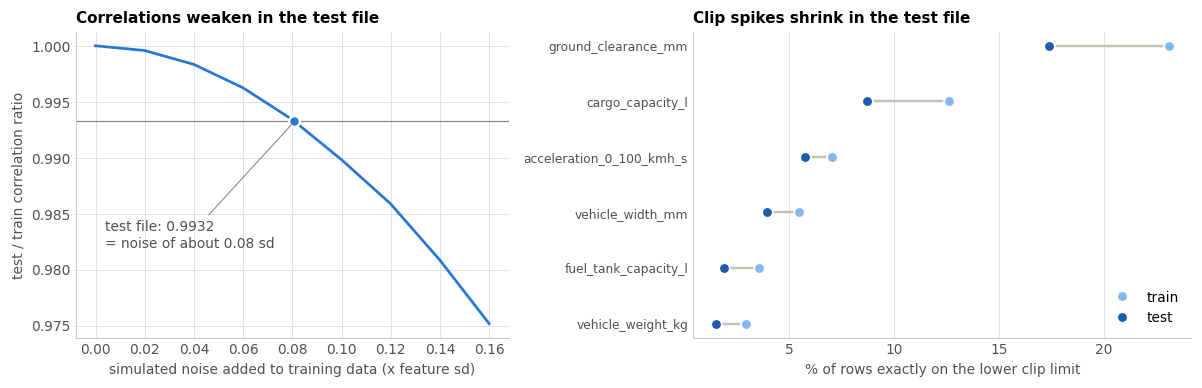

ground clearance (mm),110,111,112,113,114,115,116,117,118,119,120,121
train %,23.08,0.45,0.44,0.32,0.52,0.36,0.47,0.27,0.35,0.47,0.41,0.28
test %,17.40,1.04,1.04,1.08,1.12,0.96,0.92,0.56,0.76,0.72,0.76,0.84


In [14]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.15]})
a.plot(levels, sim, color="#2a78d6", lw=1.8)
a.axhline(observed, color=MUTED, lw=0.8)
a.plot([s_hat], [observed], "o", ms=7, color="#2a78d6", mec="white", mew=1.5)
a.annotate(f"test file: {observed:.4f}\n= noise of about {s_hat:.2f} sd", (s_hat, observed),
           xytext=(0.004, 0.982), color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.7))
a.set_xlabel("simulated noise added to training data (x feature sd)")
a.set_ylabel("test / train correlation ratio")
a.set_title("Correlations weaken in the test file")
feats = ["ground_clearance_mm", "cargo_capacity_l", "acceleration_0_100_kmh_s",
         "vehicle_width_mm", "fuel_tank_capacity_l", "vehicle_weight_kg"][::-1]
for i, f in enumerate(feats):
    j = FEATURES.index(f)
    tr, te = np.mean(X[:, j] == LO[j]) * 100, np.mean(X_test[:, j] == LO[j]) * 100
    b.plot([te, tr], [i, i], color=AXIS, lw=1.6, zorder=1)
    b.plot(tr, i, "o", ms=7, color="#86b6ef", mec="white", mew=1.2, label="train" if i == 0 else None)
    b.plot(te, i, "o", ms=7, color="#1c5cab", mec="white", mew=1.2, label="test" if i == 0 else None)
b.set_yticks(range(len(feats)), feats, fontsize=8)
b.set_xlabel("% of rows exactly on the lower clip limit")
b.grid(axis="y", visible=False)
b.legend(loc="lower right")
b.set_title("Clip spikes shrink in the test file")
fig.tight_layout()
plt.show()

j = FEATURES.index("ground_clearance_mm")
vals = np.arange(110, 122)
display(pd.DataFrame({"train %": [(X[:, j] == v).mean() * 100 for v in vals],
                      "test %": [(X_test[:, j] == v).mean() * 100 for v in vals]},
                     index=pd.Index(vals, name="ground clearance (mm)")).round(2).T)

The mass knocked off the 110 mm limit reappears just inside it (111–121 mm), so the noise was
added **after** clipping. Only about a quarter to a third of each spike moved, whereas noise on
every value would move about half: the error reaches **roughly half of the values** (about
0.12 sd each, equivalent on average to the 0.08 sd found above).

### 8.4 Adversarial validation

A classifier is trained to tell training rows (0) from test rows (1). If both come from the
same distribution its AUC is about 0.5. As a null reference, the same model separates two
random parts of the training data.

In [15]:
A = np.vstack([X, X_test])
t = np.r_[np.zeros(len(X), int), np.ones(len(X_test), int)]

def adv_model():
    return LGBMClassifier(n_estimators=300, num_leaves=15, learning_rate=0.05, subsample=0.8,
                          subsample_freq=1, colsample_bytree=0.8, min_child_samples=40, verbose=-1)

def cv_auc(M, labels, seeds=(0, 1, 2), perm=False):
    aucs, drops = [], np.zeros(M.shape[1])
    for s in seeds:
        oof, permuted = np.zeros(len(labels)), np.zeros((M.shape[1], len(labels)))
        for tr, va in StratifiedKFold(5, shuffle=True, random_state=s).split(M, labels):
            m = adv_model().fit(M[tr], labels[tr])
            oof[va] = m.predict_proba(M[va])[:, 1]
            if perm:
                rng = np.random.default_rng(s)
                for j in range(M.shape[1]):
                    Mp = M[va].copy()
                    Mp[:, j] = rng.permutation(Mp[:, j])
                    permuted[j, va] = m.predict_proba(Mp)[:, 1]
        a = roc_auc_score(labels, oof)
        aucs.append(a)
        if perm:
            drops += np.array([a - roc_auc_score(labels, permuted[j]) for j in range(M.shape[1])]) / len(seeds)
    return np.mean(aucs), np.std(aucs), drops

auc, auc_sd, drops = cv_auc(A, t, perm=True)
null = []
for s in range(3):
    idx = np.random.default_rng(s).permutation(len(X))
    labels = np.r_[np.zeros(5625, int), np.ones(1875, int)]
    null.append(cv_auc(X[idx], labels, seeds=(s,))[0])
print(f"train vs test AUC          : {auc:.3f} +- {auc_sd:.3f}")
print(f"null (two halves of train) : {np.mean(null):.3f} +- {np.std(null):.3f}")

adv = pd.DataFrame({"KS p-value": [ks_2samp(X[:, j], X_test[:, j]).pvalue for j in range(20)],
                    "single-feature AUC": [max(roc_auc_score(t, A[:, j]), 1 - roc_auc_score(t, A[:, j]))
                                           for j in range(20)],
                    "permutation AUC drop": drops}, index=FEATURES)
adv.sort_values("permutation AUC drop", ascending=False).round(4)

train vs test AUC          : 0.559 +- 0.006
null (two halves of train) : 0.504 +- 0.013


,KS p-value,single-feature AUC,permutation AUC drop
ground_clearance_mm,0.0000,0.5107,0.0282
torque_nm,0.2631,0.5041,0.0106
cargo_capacity_l,0.0067,0.5024,0.0097
vehicle_width_mm,0.6523,0.5053,0.0097
horsepower_hp,0.5464,0.5039,0.0069
acceleration_0_100_kmh_s,0.8612,0.5023,0.0067
fuel_tank_capacity_l,0.4053,0.5082,0.0064
tire_width_mm,0.1491,0.5074,0.0063
wheelbase_mm,0.4644,0.5062,0.0058
vehicle_length_mm,0.2396,0.5087,0.0057


Train and test are only weakly distinguishable, and **no feature shifts on its own** (every
single-feature AUC is about 0.5). The signal is the noise signature: shrunken clip spikes
(ground clearance, cargo, width) and slightly loosened correlations (torque with horsepower
and displacement).

### 8.5 Duplicates or near-duplicates between train and test

In [16]:
mu, sdv = X.mean(0), X.std(0)
Ztr, Zte = (X - mu) / sdv, (X_test - mu) / sdv

def nearest(Q, R, exclude_self=False):
    out = np.empty(len(Q))
    for i in range(0, len(Q), 1500):
        d2 = (Q[i:i + 1500] ** 2).sum(1)[:, None] + (R ** 2).sum(1)[None] - 2 * Q[i:i + 1500] @ R.T
        if exclude_self:
            d2[np.arange(d2.shape[0]), np.arange(i, i + d2.shape[0])] = np.inf
        out[i:i + 1500] = np.sqrt(np.maximum(d2.min(1), 0))
    return out

key = lambda M: {r.tobytes() for r in np.round(M, 4)}
print("test rows identical to a training row:", len(key(X_test) & key(X)))
d_test = nearest(Zte, Ztr)
d_ctrl = nearest(Ztr, Ztr, exclude_self=True)
q = [0, 0.001, 0.01, 0.5]
display(pd.DataFrame({"test -> nearest train row": np.quantile(d_test, q),
                      "train -> nearest other train row": np.quantile(d_ctrl, q)},
                     index=["min", "0.1%", "1%", "median"]).round(3).T)
print("a noisy re-measurement of the same vehicle would sit about 0.36 standardised units away")

test rows identical to a training row: 0


,min,0.1%,1%,median
test -> nearest train row,0.886,0.951,1.036,1.529
train -> nearest other train row,0.702,0.759,0.994,1.499


a noisy re-measurement of the same vehicle would sit about 0.36 standardised units away


### 8.6 Does the number formatting leak the class?

In [17]:
rows = []
for j, f in enumerate(FEATURES):
    v = np.round(X[:, j] * 10 ** (0 if np.all(np.round(X[:, j]) == X[:, j]) else 2)).astype(np.int64)
    if v.max() - v.min() < 100:
        continue                                        # last digit tied to the magnitude itself
    inside = (X[:, j] > LO[j]) & (X[:, j] < HI[j])      # ignore the clip spikes
    rows.append({"feature": f, "rows used": int(inside.sum()),
                 "last digit vs class p-value": chi2_contingency(pd.crosstab(v[inside] % 10, y[inside]))[1]})
pd.DataFrame(rows).set_index("feature").round(4)

,rows used,last digit vs class p-value
feature,,
engine_displacement_l,7455,0.1737
horsepower_hp,7391,0.8482
vehicle_weight_kg,7274,0.2601
wheelbase_mm,7460,0.7265
vehicle_length_mm,7208,0.6643
vehicle_width_mm,6633,0.0353
vehicle_height_mm,7254,0.1304
city_fuel_efficiency_kmpl,7191,0.8891
highway_fuel_efficiency_kmpl,7475,0.3154


With the clip spikes excluded, no last digit is related to the class – no formatting leak.

### 8.7 Class mix of the test set

We fit the final model (logistic regression, C = 0.1, trained on four noise-jittered copies –
see `02_Preprocessing`) and compare its predicted class mix with training. The EM method of
Saerens et al. also estimates the true test mix.

In [18]:
def jitter_copies(Xa, ya, sd=0.20, copies=4, seed=42):
    rng = np.random.default_rng(seed)
    col_sd = Xa.std(0, ddof=1)
    parts = [Xa] + [Xa + rng.normal(0.0, sd * col_sd, Xa.shape) for _ in range(copies)]
    return np.vstack(parts), np.concatenate([ya] * (copies + 1))

final = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=20000)).fit(*jitter_copies(X, y))
P_test = final.predict_proba(X_test)
train_mix = np.bincount(y, minlength=3) / len(y)
prior = train_mix.copy()
for _ in range(200):                       # EM prior adjustment
    w = P_test * (prior / train_mix)
    w /= w.sum(1, keepdims=True)
    prior = w.mean(0)
pred = P_test.argmax(1)
display(pd.DataFrame({"train labels": train_mix, "test predicted": np.bincount(pred, minlength=3) / len(pred),
                      "test true mix (EM estimate)": prior},
                     index=[CLASS[c][0] for c in range(3)]).mul(100).round(2))
print(f"chi-square, test predictions vs train mix: p = "
      f"{chisquare(np.bincount(pred, minlength=3), train_mix * len(pred)).pvalue:.3f}")
print(f"re-weighting to the EM mix would change {(w.argmax(1) != pred).sum()} of {len(pred):,} predictions")

,train labels,test predicted,test true mix (EM estimate)
Sedan,33.85,33.60,33.26
SUV,33.20,33.16,33.51
Sports Car,32.95,33.24,33.23


chi-square, test predictions vs train mix: p = 0.945
re-weighting to the EM mix would change 6 of 2,500 predictions


## 9. Summary

* The data is clean apart from **2,500 exact duplicates (25%)**, which are removed.
* `vehicle_id` is an identifier and is excluded.
* The three classes are **balanced** (33.9 / 33.2 / 32.9%), so accuracy is a fair metric.
* Features are **highly correlated** (90 of 190 pairs above |r| = 0.5), which hurts Naive Bayes.
* The classes are overlapping, nearly linearly separable clouds; **sedans sit in the middle**.
* Many values are **clipped** to fixed limits.
* The test file carries **mild extra noise** – about 0.08 sd on average, added after clipping
  and reaching roughly half of the values. There is no other shift, no train–test overlap and
  no formatting leak.

Every model in `03_Models` is therefore scored **under that measured noise**, not on clean data.